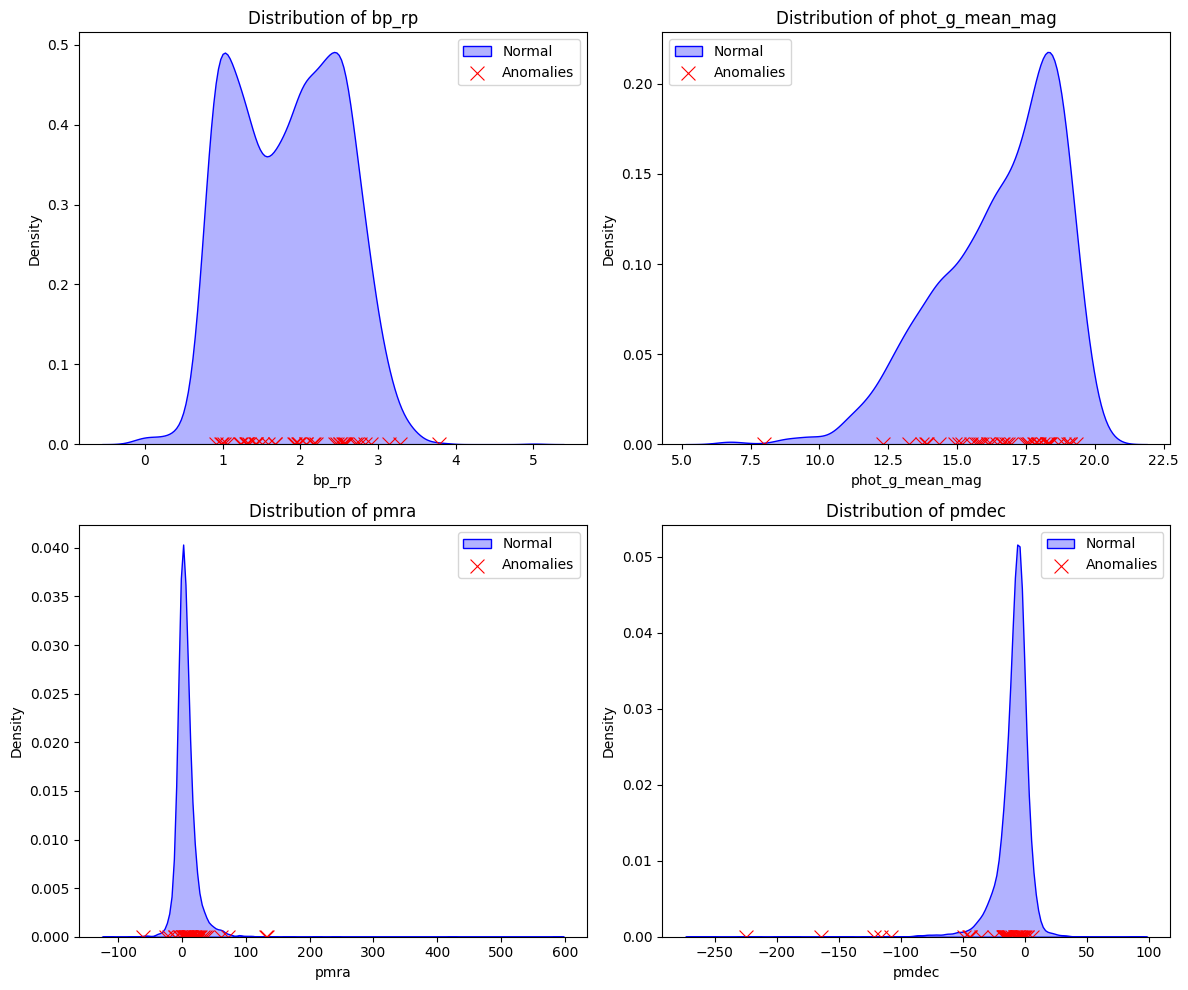

In [2]:
# Cell 1: Imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Cell 2: Load Data
df_validated = pd.read_csv('../results/candidates/validated_candidates.csv', dtype={'source_id': str}) # Fix: force str here
df_clean = pd.read_csv('../data/intermediate/gaia_clean.csv', dtype={'source_id': str})

# Merge features back into the anomalies
anomalies = df_validated[df_validated['known_object'] == False]
anomaly_features = pd.merge(anomalies[['source_id']], df_clean, on='source_id', how='left')

# Sample normal objects for comparison
normal_objects = df_clean[~df_clean['source_id'].isin(df_validated['source_id'])].sample(n=5000, random_state=42)
# Cell 3: Plot Feature Distributions (e.g., Color and Proper Motion)
features_to_plot = ['bp_rp', 'phot_g_mean_mag', 'pmra', 'pmdec']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, feat in enumerate(features_to_plot):
    if feat in anomaly_features.columns:
        sns.kdeplot(normal_objects[feat], ax=axes[i], label='Normal', color='blue', fill=True, alpha=0.3)
        sns.scatterplot(x=anomaly_features[feat], y=np.zeros(len(anomaly_features)), 
                        ax=axes[i], color='red', label='Anomalies', marker='x', s=100)
        axes[i].set_title(f'Distribution of {feat}')
        axes[i].legend()

plt.tight_layout()
plt.show()